<a href="https://colab.research.google.com/github/yamenetoo/Statistical-Repository/blob/main/Else/Dr%20homai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Density of a Normal–Uniform Mixture: $Z = W X_1 + (1-W) X_2$

Let $X_1, X_2 \sim N(0,1)$ be independent and let $W \sim U(0,1)$ be independent of both. This notebook studies the density of

$$Z = W\,X_1 + (1-W)\,X_2$$

by three routes and compares them with the exact result:

1. **Polynomial moment matching**: a degree-$N$ polynomial on $[a,b]$ whose moments equal the sample moments of $Z$.
2. **Parametric fit**: a normal distribution fitted by maximum likelihood (`fitdistrplus`).
3. **Theory**: moments of $Z$ and its exact density, obtained by conditioning on $W$.

**Contents**: 1 Setup · 2 Simulation · 3 Polynomial moment matching · 4 Normal fit · 5 Theory · 6 Comparison · 7 Conclusions

> **Runtime**: R. Packages: `ggplot2`, `fitdistrplus`.

## 1. Setup

In [1]:
# install.packages(c("fitdistrplus", "ggplot2"))   # first run only
suppressPackageStartupMessages({
  library(ggplot2)
  library(fitdistrplus)
})

# ---- Configuration -------------------------------------------------------
SEED        <- 123
N_OBS       <- 1000
POLY_DEGREE <- 10
SUPPORT     <- c(-3, 3)     # interval on which the polynomial density is defined
GRID_STEP   <- 0.01

set.seed(SEED)

## 2. Simulation

Conditional on $W = w$, $Z$ is a sum of two independent normals, so $Z \mid W=w \sim N\!\left(0,\; w^2 + (1-w)^2\right)$. Marginally $Z$ is a *scale mixture of normals*.

In [2]:
simulate_mixture <- function(n) {
  X1 <- rnorm(n)
  X2 <- rnorm(n)
  W  <- runif(n)
  data.frame(X1 = X1, X2 = X2, W = W, Z = W * X1 + (1 - W) * X2)
}

sim <- simulate_mixture(N_OBS)
Z   <- sim$Z
head(sim)

,X1,X2,W,Z
,<dbl>,<dbl>,<dbl>,<dbl>
1,-0.56047565,-0.99579872,0.3044642,-0.86325844
2,-0.23017749,-1.03995504,0.8328188,-0.36555709
3,1.55870831,-0.01798024,0.5936475,0.91801699
4,0.07050839,-0.13217513,0.8071966,0.03143033
5,0.12928774,-2.54934277,0.2940508,-1.76168939
6,1.71506499,1.04057346,0.1410852,1.13573424


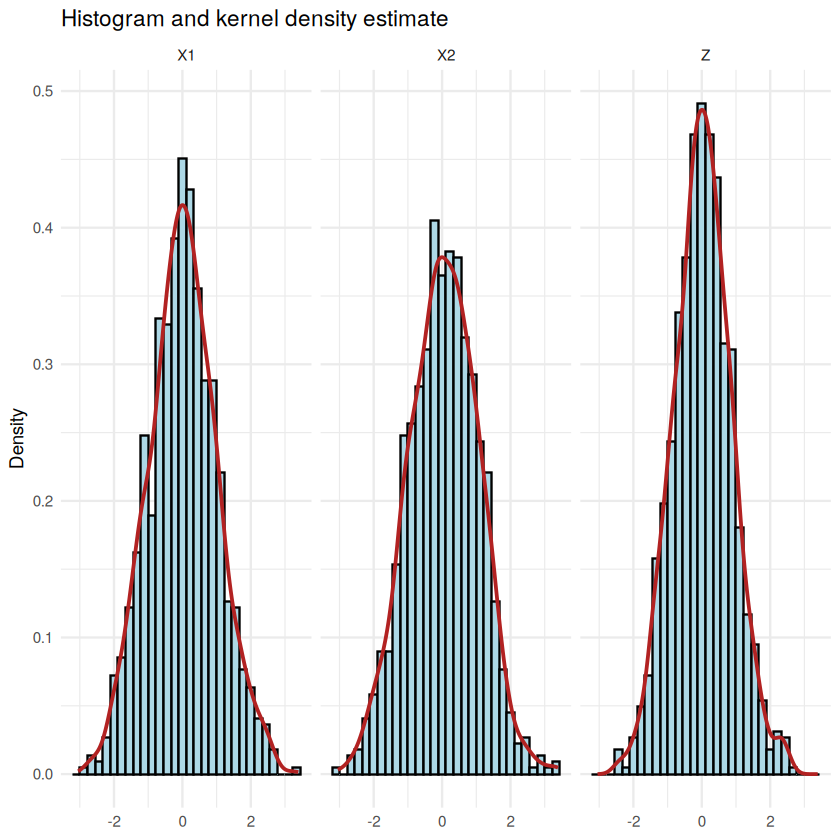

In [3]:
long <- stack(sim[c("X1", "X2", "Z")])

ggplot(long, aes(x = values)) +
  geom_histogram(aes(y = after_stat(density)), bins = 30, fill = "lightblue", colour = "black") +
  geom_density(colour = "firebrick", linewidth = 0.8) +
  facet_wrap(~ ind, nrow = 1) +
  labs(title = "Histogram and kernel density estimate", x = NULL, y = "Density") +
  theme_minimal()

## 3. Polynomial moment matching

Look for $f(x) = \sum_{j=0}^{N} w_j x^j$ on $[a,b]$ such that $\int_a^b x^r f(x)\,dx = m_r$ for $r = 0,\dots,N$, where $m_r$ is the sample mean of $Z^r$. This is the linear system $M\,w = m$ with

$$M_{rj} = \int_a^b x^{r+j}\,dx = \frac{b^{\,r+j+1} - a^{\,r+j+1}}{r+j+1}.$$

$M$ is a Hilbert-type matrix and becomes ill-conditioned as $N$ grows. The fitted polynomial is also not guaranteed to be non-negative, so the code reports both diagnostics.

In [4]:
fit_polynomial_density <- function(z, degree, lower, upper) {
  k       <- 0:degree
  moments <- vapply(k, function(r) mean(z^r), numeric(1))
  power   <- outer(k, k, "+") + 1
  M       <- (upper^power - lower^power) / power
  list(coef = solve(M, moments), condition = kappa(M, exact = TRUE), degree = degree)
}

eval_polynomial <- function(fit, x) {
  drop(outer(x, 0:fit$degree, "^") %*% fit$coef)
}

poly_fit <- fit_polynomial_density(Z, POLY_DEGREE, SUPPORT[1], SUPPORT[2])
grid     <- seq(SUPPORT[1], SUPPORT[2], by = GRID_STEP)
f_poly   <- eval_polynomial(poly_fit, grid)

cat(sprintf("condition number of M : %.3g\n", poly_fit$condition))
cat(sprintf("minimum of the fit     : %.4f (negative values mean the polynomial is not a valid density)\n", min(f_poly)))
cat(sprintf("mass on [%g, %g]       : %.4f\n", SUPPORT[1], SUPPORT[2], sum(f_poly) * GRID_STEP))

condition number of M : 2.27e+10


minimum of the fit     : -0.0186 (negative values mean the polynomial is not a valid density)


mass on [-3, 3]       : 0.9999


## 4. Normal fit by maximum likelihood

In [5]:
norm_fit <- fitdist(Z, "norm")
summary(norm_fit)

f_norm_mle <- dnorm(grid, mean = norm_fit$estimate["mean"], sd = norm_fit$estimate["sd"])

Fitting of the distribution ' norm ' by maximum likelihood 
Parameters : 
       estimate Std. Error
mean 0.02486037 0.02672779
sd   0.84520679 0.01889928
Loglikelihood:  -1250.765   AIC:  2505.529   BIC:  2515.345 
Correlation matrix:
     mean sd
mean    1  0
sd      0  1


## 5. Theory

**Moments.** Conditioning on $W$ and using $E[X_i]=0$, $\mathrm{Var}(X_i)=1$:

$$E[Z] = 0, \qquad \mathrm{Var}(Z) = E\!\left[W^2 + (1-W)^2\right] = \tfrac13 + \tfrac13 = \tfrac23 .$$

The fourth moment shows that $Z$ is **not** normal. With $s(W) = W^2 + (1-W)^2 = 1 - 2W + 2W^2$,

$$E[Z^4] = 3\,E\!\left[s(W)^2\right] = 3 \cdot \tfrac{7}{15} = \tfrac75, \qquad \text{kurtosis} = \frac{7/5}{(2/3)^2} = 3.15,$$

so the excess kurtosis is $0.15 > 0$ (slightly heavier tails than a normal with the same variance).

**Exact density.**

$$f_Z(z) = \int_0^1 \frac{1}{\sqrt{s(w)}}\,\varphi\!\left(\frac{z}{\sqrt{s(w)}}\right) dw, \qquad s(w) = w^2 + (1-w)^2,$$

which is evaluated below by numerical integration. The normal $N(0, 2/3)$ with the **same mean and variance** is shown for reference (standard deviation $\sqrt{2/3} \approx 0.816$).

In [6]:
cond_sd <- function(w) sqrt(w^2 + (1 - w)^2)

exact_density <- function(z) {
  vapply(z, function(zi) {
    integrate(function(w) dnorm(zi, mean = 0, sd = cond_sd(w)), lower = 0, upper = 1)$value
  }, numeric(1))
}

f_exact       <- exact_density(grid)
f_norm_theory <- dnorm(grid, mean = 0, sd = sqrt(2/3))

excess_kurtosis <- function(x) mean((x - mean(x))^4) / mean((x - mean(x))^2)^2 - 3

data.frame(
  quantity    = c("mean", "variance", "excess kurtosis"),
  theoretical = c(0, 2/3, 0.15),
  sample      = c(mean(Z), var(Z), excess_kurtosis(Z))
)

quantity,theoretical,sample
<chr>,<dbl>,<dbl>
mean,0.0000000,0.02486037
variance,0.6666667,0.71508961
excess kurtosis,0.1500000,0.08963192


## 6. Comparison

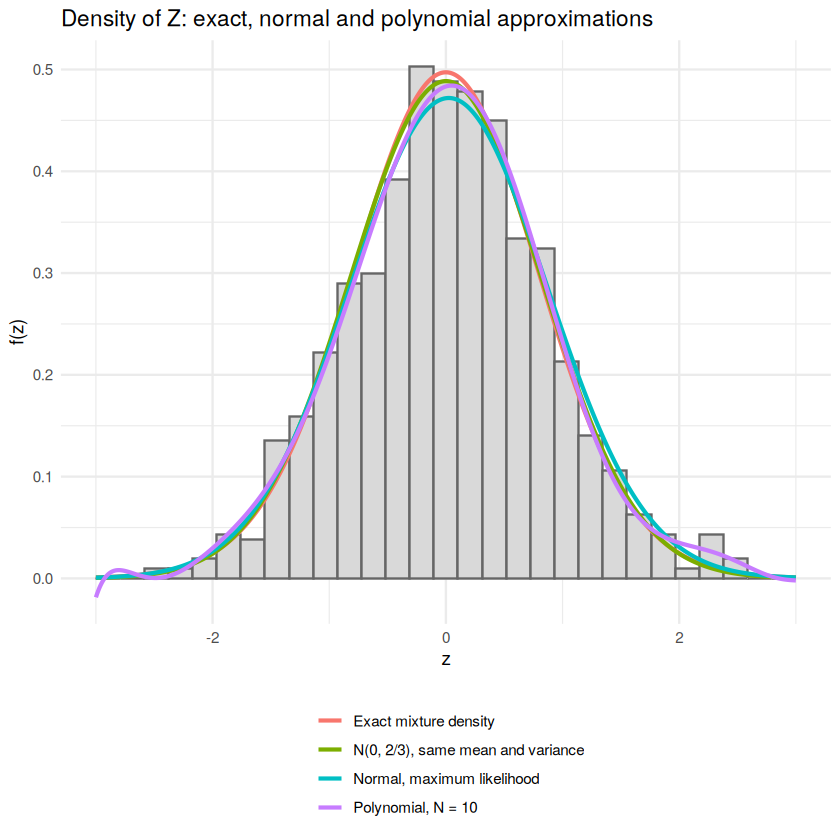

In [7]:
curves <- rbind(
  data.frame(z = grid, density = f_exact,       method = "Exact mixture density"),
  data.frame(z = grid, density = f_norm_theory, method = "N(0, 2/3), same mean and variance"),
  data.frame(z = grid, density = f_norm_mle,    method = "Normal, maximum likelihood"),
  data.frame(z = grid, density = f_poly,        method = sprintf("Polynomial, N = %d", POLY_DEGREE))
)

ggplot() +
  geom_histogram(data = data.frame(Z = Z), aes(x = Z, y = after_stat(density)),
                 bins = 30, fill = "grey85", colour = "grey40") +
  geom_line(data = curves, aes(x = z, y = density, colour = method), linewidth = 0.9) +
  labs(title = "Density of Z: exact, normal and polynomial approximations",
       x = "z", y = "f(z)", colour = NULL) +
  theme_minimal() +
  theme(legend.position = "bottom", legend.direction = "vertical")

In [8]:
# Integrated squared error against the exact density on the grid
ise <- function(f) sum((f - f_exact)^2) * GRID_STEP

data.frame(
  method = c("N(0, 2/3), same mean and variance", "Normal, maximum likelihood",
             sprintf("Polynomial, N = %d", POLY_DEGREE)),
  ISE    = c(ise(f_norm_theory), ise(f_norm_mle), ise(f_poly))
)

method,ISE
<chr>,<dbl>
"N(0, 2/3), same mean and variance",7.823052e-05
"Normal, maximum likelihood",7.957026e-04
"Polynomial, N = 10",5.383035e-04


## 7. Conclusions

* $E[Z]=0$ and $\mathrm{Var}(Z)=2/3$, but $Z$ is **not exactly normal**: it is a scale mixture of normals with excess kurtosis $0.15$. A normal with the same mean and variance is a close but not exact description.
* The maximum-likelihood normal fit follows the *sample* (here the estimated standard deviation is larger than $\sqrt{2/3}$ by ordinary sampling variability), whereas $N(0, 2/3)$ is built from theory. Against the exact density, the theoretical $N(0,2/3)$ has by far the smallest integrated squared error in this run.
* The degree-10 polynomial reproduces the first ten sample moments by construction and is competitive with the maximum-likelihood normal. It depends on the truncation to $[-3,3]$, the moment system is ill-conditioned (condition number about $10^{10}$), and the fit dips below zero, so it is not a valid density.
* The numerical values above depend on the simulated sample (`SEED`, `N_OBS`); the theoretical statements do not.